In [2]:
import math as math
import numpy as np
import random as random
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import HTML
%matplotlib inline
from tqdm import tqdm
import numpy as np
import networkx as nx


Step 0 of 1000000.0: 100%|██████████| 1000000/1000000.0 [00:11<00:00, 89197.57it/s]


Matrix:
[[ 6  0  6  5  5  6  6  5  5  5]
 [ 8  8  8  8  8  1  8  8  8  8]
 [ 2 11  2 11 11  2 11 11 11 11]
 [15 15 15  3 15  3 15 15  3 15]
 [14 14 14  4  9 14  9  9  9  9]
 [ 5  0  0  6  0  6  6  6  0  6]
 [ 0  0  5  0  0  5  5  6  6  0]
 [10 10 10  7 10 10 10  7  7  7]
 [ 1  8  1  8  8  1  1  1  1  1]
 [ 4  4 14  9  4 14  9 14  9 14]
 [10 10  7  7 10 10  7  7  7  7]
 [ 2  2  2 11  2  2 11  2  2  2]
 [12 18 16 18 18 16 12 12 12 16]
 [19 17 19 17 17 17 19 13 13 17]
 [14  9  4 14  9 14  9  4  9  9]
 [15  3  3  3 15 15  3  3 15  3]
 [12 16 18 12 16 12 18 12 12 12]
 [19 19 19 13 13 13 13 19 13 19]
 [12 18 12 12 12 12 12 16 16 16]
 [17 13 13 17 17 13 19 17 13 13]]


Text(0.5, 0, 'One step is 5000 steps in sim')

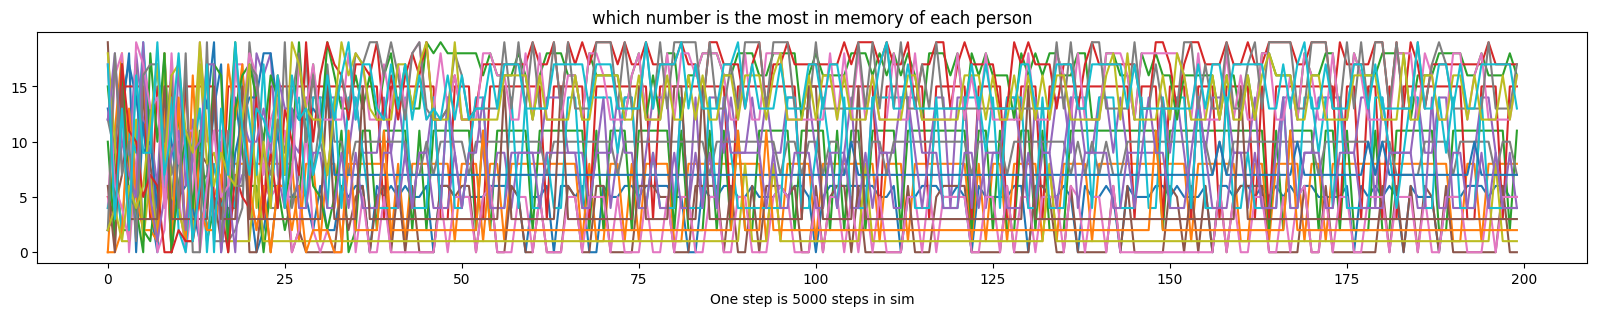

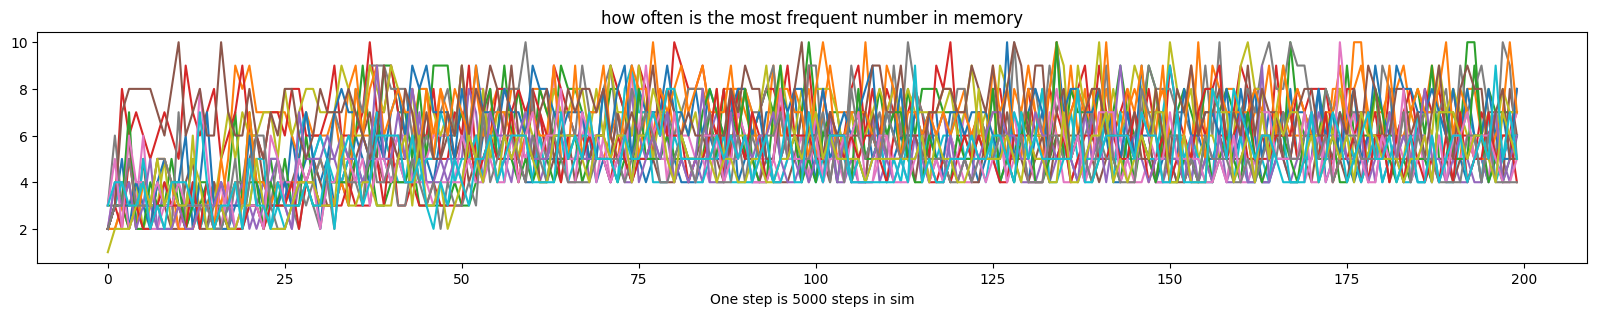

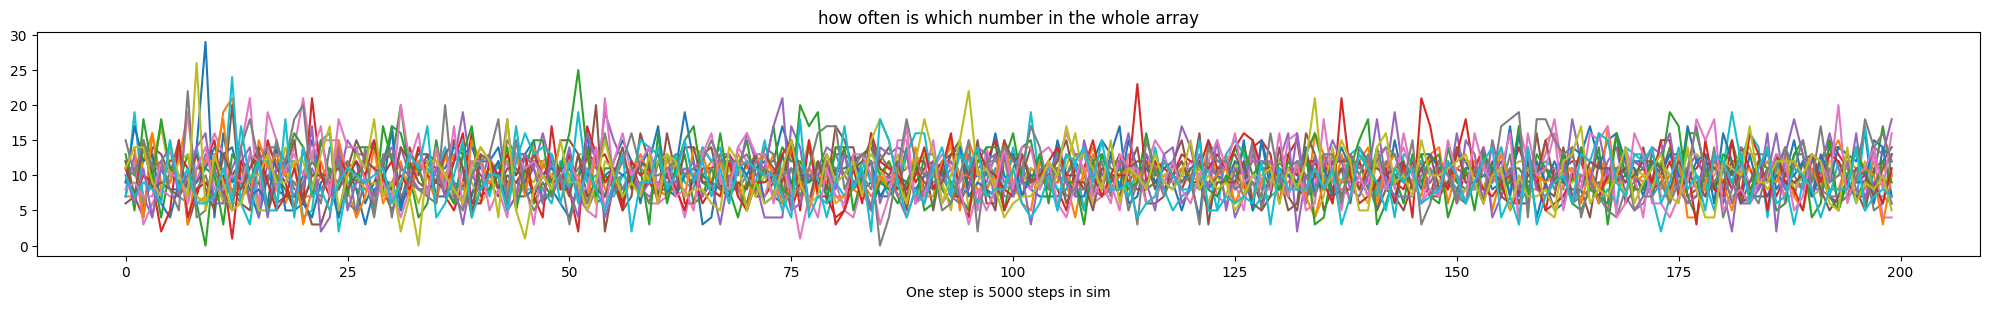

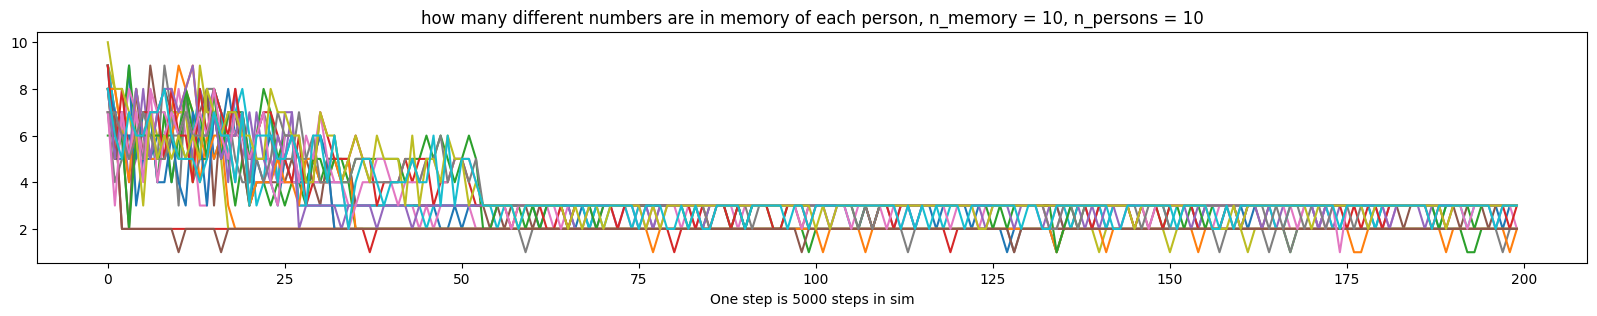

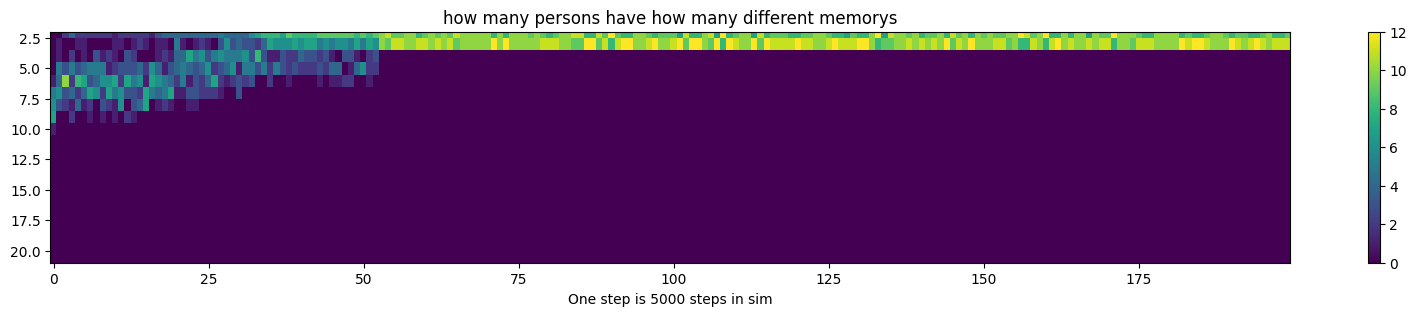

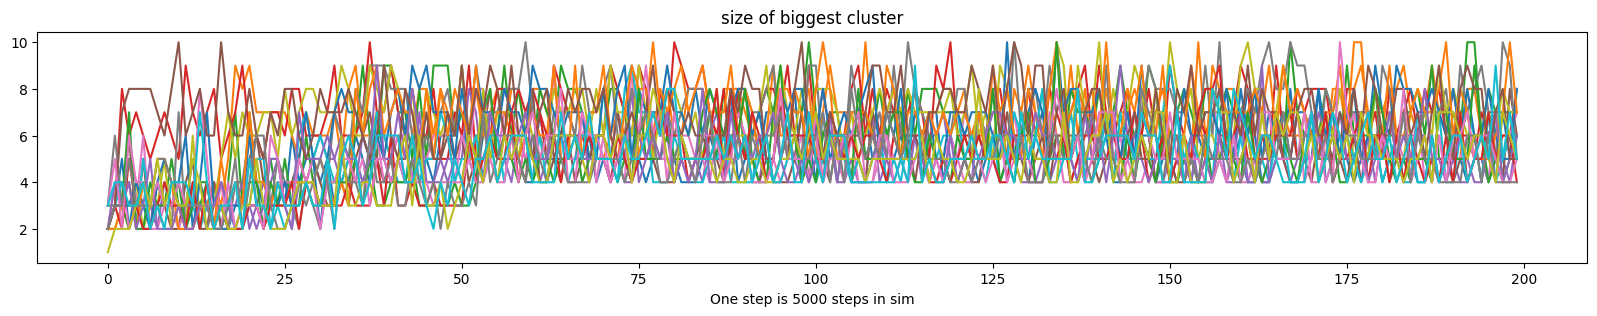

In [ ]:

noise_p = 0# 1e-5

n_memory = 10
n_persons = 20
n_max = 10e5

#datacollection
points = 200
network_graphs = 10 #choose

ingraph = int(n_max/points)

innetworkgraph = points//network_graphs*ingraph
#innetworkgraph = int(n_max/network_graphs)



def givarray(n_persons,n_memory):
    array = np.random.randint(0,n_persons-1,size=(n_persons,n_memory))
    for i in np.arange(0,n_persons-1):
        array[i,array[i,:] == i] = n_persons-1
    return array
array = givarray(n_memory=n_memory,n_persons=n_persons)

def find_most_frequent(row):
    unique_vals, counts = np.unique(row, return_counts=True)
    max_count = np.max(counts)
    numb_different_m = len(unique_vals)
    most_frequent = unique_vals[counts == max_count]
    return most_frequent[0], max_count, numb_different_m
def find_most_frequent_array(array):
    frequency_in_array_vec = np.bincount(array.flatten())
    frequency_in_array_vec = np.pad(frequency_in_array_vec,(0,n_persons-len(frequency_in_array_vec)),'constant')
    most_frequent_per_row = np.zeros(n_persons)
    max_count_per_row = np.zeros(n_persons)
    numb_different_m_row = np.zeros(n_persons)
    for i, row in enumerate(array):
        most_frequent_per_row_z, max_count_per_row_z, numb_different_m_z = find_most_frequent(row)
        most_frequent_per_row[i] = most_frequent_per_row_z
        max_count_per_row[i] = max_count_per_row_z
        numb_different_m_row[i] = numb_different_m_z
    return most_frequent_per_row,max_count_per_row,frequency_in_array_vec, numb_different_m_row

def sizedistribution(n_persons, array2):
    size = np.zeros((n_persons,1))
    for k in np.arange(0, n_persons):
        pers_i = array2[k, :]
        uni = np.unique(pers_i) 
        liste = []
        unineu = []
        for m in np.arange(0,n_persons+5):
            liste = []
            for m in uni:
                liste.extend(array2[m, :])
            unineu = np.unique(np.array(liste))
            if np.array_equal(uni, unineu):
                break
            uni = unineu.copy()
        size[k] = np.copy(len(uni))
    size =  np.int16(np.array(size).flatten())
    a = np.bincount(size)
    sizedist =  np.pad(a,(0,n_persons-len(a)+1),'constant')[1:]  / np.arange(1,n_persons+1)
    return sizedist

#testttetstttett


    #array = changearray(np.copy(array))

most_frequent_per_row= []
max_count_per_row = []
frequency_in_array = []
numb_different_m_array = []
numb_max_count_per_row_array = []
adj_matrix_array = []
sizedistribution_array = []

for i in tqdm(np.arange(0, n_max), total=n_max, desc="Step {0} of {1}".format(0, n_max)): 
    
    person1_rand = np.random.randint(0,n_persons)
    memory1_rand = np.random.randint(0,n_memory)

    person1_memory = array[person1_rand]

    if random.random() < noise_p:
        person2_index = np.random.randint(0,n_persons)
    else:
        person2_index = person1_memory[memory1_rand]
    
    if person2_index != person1_rand:# or newp_index == p_rand:
        #print(1111,person2_index,person1_rand)
        person2_memory = array[person2_index]
        person2_memory = np.copy(person2_memory)


        m_rand2 = np.random.randint(0,n_memory)
        m_rand3 = np.random.randint(0,n_memory)
        m_rand4 = np.random.randint(0,n_memory)
        #print(m_rand,p_rand, newp_index, newp_memory)
        
        
        person2_memory[m_rand3] = person1_memory[m_rand4]
        person2_memory[m_rand2] = person1_rand

        array[person2_index] = person2_memory

    if i % ingraph == 0:
        most_frequent_per_row_vec, max_count_per_row_vec, frequency_in_array_vec,numb_different_m_row_vec = find_most_frequent_array(array)
        most_frequent_per_row.append(most_frequent_per_row_vec)
        max_count_per_row.append(max_count_per_row_vec)
        frequency_in_array.append(frequency_in_array_vec)
        numb_different_m_array.append(numb_different_m_row_vec)

        numb_max_count_per_row = np.copy(np.bincount(np.int16(np.ravel(np.vstack(numb_different_m_row_vec)))))
        numb_max_count_per_row = np.pad(numb_max_count_per_row,(0,n_persons+3-len(numb_max_count_per_row)),'constant')
        numb_max_count_per_row_array.append(numb_max_count_per_row)
        
        if i % innetworkgraph == 0:
            adj_matrix = np.zeros((n_persons,n_persons))
            for j in np.arange(0,n_persons):
                a = np.bincount(array[j,:])
                adj_matrix[j,:] =  np.pad(a,(0,n_persons-len(a)),'constant')  
            adj_matrix  = np.transpose(adj_matrix)
            adj_matrix_array.append(adj_matrix)
            sizedistribution_array.append(sizedistribution(n_persons,array2=array))
            

sizedistribution_array = np.array(sizedistribution_array)
print("Matrix:")
print(array)

#print(most_frequent_per_row)
#print(max_count_per_row)

most_frequent_per_row=(np.vstack(most_frequent_per_row))
max_count_per_row = np.vstack(max_count_per_row)
#print(most_frequent_per_row)
plt.figure(figsize=(20,3))
plt.plot(most_frequent_per_row)
plt.title("which number is the most in memory of each person")
plt.xlabel(f'One step is {ingraph} steps in sim')

plt.figure(figsize=(20,3))
plt.plot(max_count_per_row)
plt.title("how often is the most frequent number in memory")
plt.xlabel(f'One step is {ingraph} steps in sim')

plt.figure(figsize=(20,3))
plt.plot(frequency_in_array)
plt.title("how often is which number in the whole array")
#plt.legend([f"Person {i}" for i in range(0, n_persons)], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.xlabel(f'One step is {ingraph} steps in sim')

plt.figure(figsize=(20,3))
plt.plot(numb_different_m_array)
plt.title(f"how many different numbers are in memory of each person, n_memory = {n_memory}, n_persons = {n_memory}")
plt.xlabel(f'One step is {ingraph} steps in sim')

plt.figure(figsize=(20,3))
img = plt.imshow(np.transpose(np.vstack(numb_max_count_per_row_array)), aspect='auto')
plt.ylim(n_persons+1,2) 
cbar = plt.colorbar(img)
plt.title(f'how many persons have how many different memorys')
plt.xlabel(f'One step is {ingraph} steps in sim')


plt.figure(figsize=(20,3))
plt.plot(max_count_per_row)
plt.title("size of biggest cluster")
plt.xlabel(f'One step is {ingraph} steps in sim')


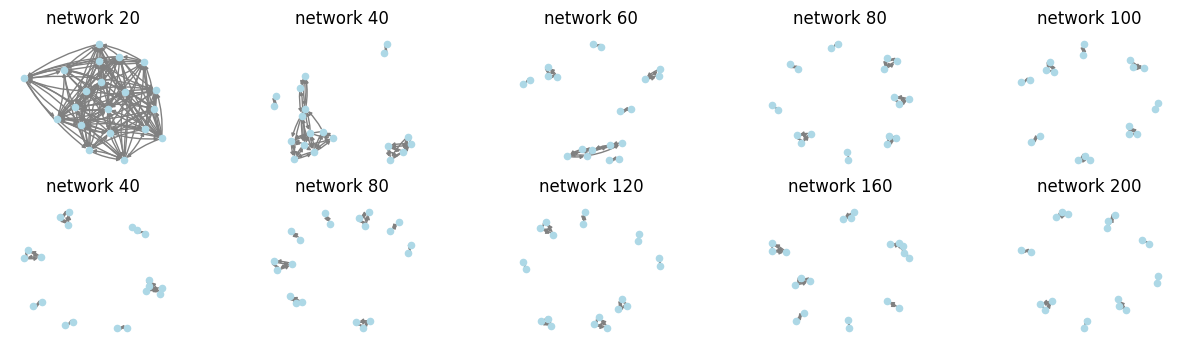

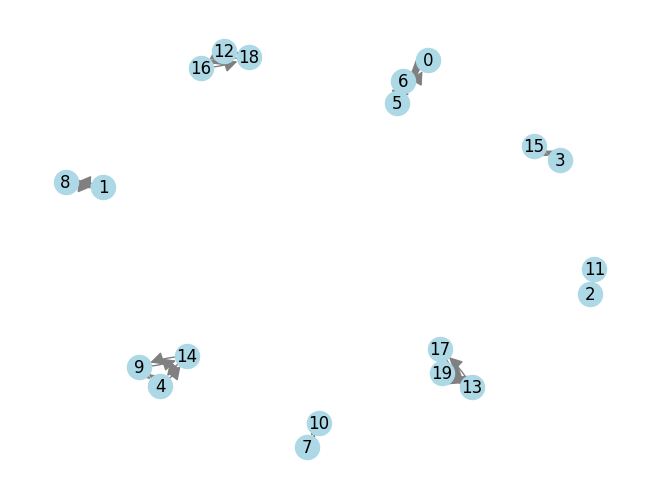

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 2. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 4. 2. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 4. 4. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 4. 4. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 4. 4. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 4. 4. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 4. 4. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 4. 4. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 4. 4. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


In [122]:
rows = 2
cols = network_graphs // rows  # Ensure integer division

fig, axes = plt.subplots(rows, cols, figsize=(15, 4))

for l in range(rows):
    for k in range(cols):
        index = l * cols + k 
        adj_matrix = adj_matrix_array[index]
        
        nodes = np.arange(0, n_persons)
        adj_matrix = adj_matrix * (np.ones((n_persons, n_persons)) - np.identity(n_persons))
        
        # Create a MultiDiGraph for multiple edges
        G = nx.MultiDiGraph()
        size = len(nodes)
        for i in range(size):
            for j in range(size):
                if adj_matrix[i, j] != 0:
                    G.add_edge(nodes[i], nodes[j], weight=adj_matrix[i, j])

        # Normalize weights: Convert higher weights into stronger attraction (smaller `k`)
        edge_weights = np.sqrt(np.sqrt(np.sqrt([G[u][v][0]['weight'] for u, v in G.edges()]))) / 2
        k_factor = 1 / (np.mean(edge_weights) + 1)  # Avoid division by zero

        # Apply weighted spring layout
        pos = nx.spring_layout(G, weight="weight", k=k_factor)

        # Draw the network graph
        nx.draw(G, pos, with_labels=False, node_color="lightblue", edge_color="gray",
                node_size=20, arrowsize=5, connectionstyle="arc3,rad=0.1", ax=axes[l, k])

        # Set title
        #axes[l, k].set_title(f"Network {index}")
        axes[l,k].set_title(f"network {np.int16((k+1)*(l+1)/(ingraph/innetworkgraph))}")

plt.subplots_adjust(wspace=0.5)
plt.figure()
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray",
                node_size=300, arrowsize=20, connectionstyle="arc3,rad=0.1")
plt.show()
#print(array)
print(sizedistribution_array)


[20. 11.  6.  3.  3.  3.  3.  3.  3.  3.]


C:\Users\jakob\AppData\Local\Temp\ipykernel_71560\511696911.py:5: RuntimeWarning: invalid value encountered in divide
  g =(sizedistribution_array/sizedistribution_array)


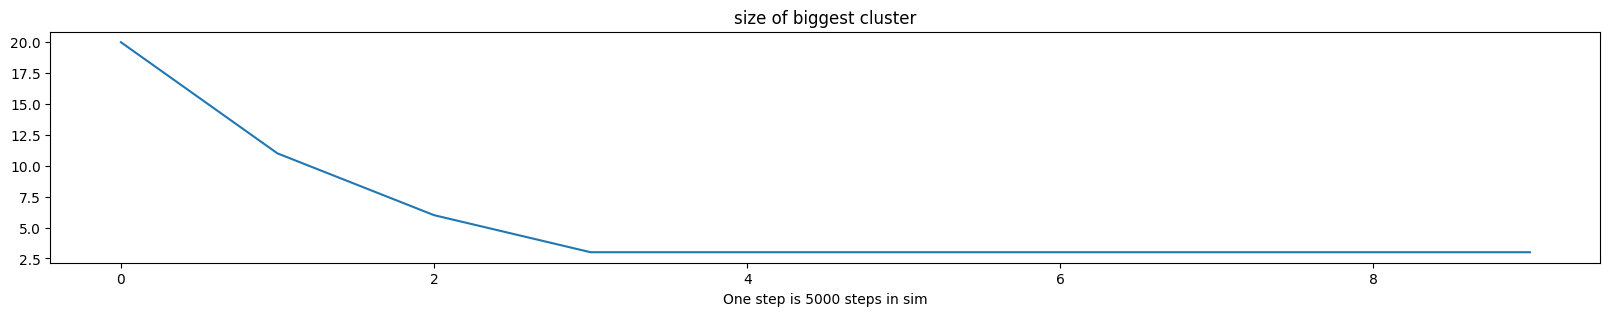

In [125]:

plt.figure(figsize=(20,3))

plt.title("size of biggest cluster")
plt.xlabel(f'One step is {ingraph} steps in sim')
g =(sizedistribution_array/sizedistribution_array)
mask = (np.arange(0,n_persons)*np.ones((n_memory,1)))
b = np.zeros((n_memory,n_persons))
b[g == 1] = mask[g == 1]
plt.plot(np.max(b,1)+1)
print(np.max(b,1)+1)

In [90]:
array2 = np.copy(array)
n_persons = 15
def sizedistribution(n_persons, array2):
    size = np.zeros((n_persons,1))
    for k in np.arange(0, n_persons):
        pers_i = array2[k, :]
        numb = np.bincount(pers_i)
        uni = np.unique(pers_i) 
        liste = []
        unineu = []

        for m in np.arange(0,n_persons+5):
            #print("yes")
            liste = []
            for m in uni:
                liste.extend(array2[m, :])
            unineu = np.unique(np.array(liste))
            if np.array_equal(uni, unineu):
                print("break")
                break
            uni = unineu.copy()
        size[k] = np.copy(len(uni))
    size =  np.int16(np.array(size).flatten())
    print(size)
    a = np.bincount(size)
    sizedist =  np.pad(a,(0,n_persons-len(a)),'constant')[1:]  / np.arange(1,n_persons)
    return sizedist

print(a)
print(sizedist)

break
break
break
break
break
break
break
break
break
break
break
break
break
break
break
[4 3 4 2 3 4 3 4 3 3 3 3 3 2 3]
[0 0 2 9 4]
[0. 1. 3. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
edge_weights = np.sqrt(np.sqrt(np.sqrt([G[u][v][0]['weight'] for u, v in G.edges()])+50))
#edge_weights = ([G[u][v][0]['weight'] for u, v in G.edges()])
print(edge_weights)